# Proyecto Final de Minería de Datos
## Bank Marketing — Notebook de preparación de datos

**Integrantes:** Mariana Arbeláez, María Lucía Cadavid y Juan Manuel Arias
**Fuente:** [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)

### Alcance de este notebook
Este notebook cubre la comprensión de los datos, el análisis exploratorio, la limpieza y la preparación básica exigida para el entregable de preparación de datos.

**Según la guía, aquí NO se incluye ingeniería de características, balanceo de clases ni transformaciones para modelado.** Esos pasos se desarrollarán coordinadamente en el notebook de creación y evaluación de modelos.

#CRISP-DM

## 1. Entendimiento del negocio

### Descripción del negocio
Las entidades bancarias realizan campañas de marketing para ofrecer depósitos a plazo a sus clientes.

### Problema
No todos los clientes contactados aceptan la oferta. El banco necesita información que ayude a priorizar a los clientes con mayor probabilidad de contratar el producto.

### Objetivo de minería
Desarrollar un modelo de clasificación que prediga si un cliente contratará un depósito a plazo, utilizando variables disponibles antes de realizar la llamada.

### Variable objetivo
`y`: `yes` si el cliente contrató el depósito y `no` si no lo contrató.

### Decisión sobre el momento de predicción
El proyecto se plantea **antes de la llamada**, para priorizar clientes. Por ello, la variable `duration` (duración de la llamada) se documenta, pero se excluirá posteriormente del conjunto de predictores del modelo porque solo se conoce después de realizar el contacto. Esta exclusión se aplicará en el notebook de modelado, no como transformación de este notebook de preparación.

## 2. Instalación de librerías

In [2]:
%pip -q install ucimlrepo ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 2.9 MB/s eta 0:00:00


## 3. Importación de librerías

In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from ydata_profiling import ProfileReport

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("entregables_preparacion_bank_marketing")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


/tmp/ipykernel_532/1121193660.py:8: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## 4. Carga del dataset Bank Marketing

In [4]:
# Carga automática desde UCI. Requiere conexión a internet.
bank_marketing = fetch_ucirepo(id=222)
X_uci = bank_marketing.data.features.copy()
y_uci = bank_marketing.data.targets.copy()

df_original = pd.concat([X_uci, y_uci], axis=1)
df_original.columns = [str(c).strip() for c in df_original.columns]

target_col = next((c for c in df_original.columns if c.lower() == "y"), None)
if target_col is None:
    raise ValueError("No se encontró la variable objetivo y.")
if target_col != "y":
    df_original = df_original.rename(columns={target_col: "y"})

for col in df_original.select_dtypes(include=["object", "string"]).columns:
    df_original[col] = df_original[col].astype("string").str.strip()

df = df_original.copy(deep=True)
print("Dataset cargado.")
print("Dimensiones:", df.shape)
display(df.head())

Dataset cargado.
Dimensiones: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,<NA>,5,may,261,1,-1,0,<NA>,no
1,44,technician,single,secondary,no,29,yes,no,<NA>,5,may,151,1,-1,0,<NA>,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,<NA>,5,may,76,1,-1,0,<NA>,no
3,47,blue-collar,married,<NA>,no,1506,yes,no,<NA>,5,may,92,1,-1,0,<NA>,no
4,33,<NA>,single,<NA>,no,1,no,no,<NA>,5,may,198,1,-1,0,<NA>,no


## 5. Verificación de requisitos mínimos

In [5]:
print(f"Registros: {len(df):,}")
print(f"Variables, incluida la objetivo: {df.shape[1]}")
print("Cumple mínimo 400 registros:", len(df) >= 400)
print("Cumple mínimo 10 variables:", df.shape[1] >= 10)

assert len(df) >= 400
assert df.shape[1] >= 10
assert "y" in df.columns

Registros: 45,211
Variables, incluida la objetivo: 17
Cumple mínimo 400 registros: True
Cumple mínimo 10 variables: True


## 6. Información general y tipos de datos

In [6]:
df.info()
display(pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(dropna=False),
    "faltantes": df.isna().sum()
}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  string
 2   marital      45211 non-null  string
 3   education    43354 non-null  string
 4   default      45211 non-null  string
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  string
 7   loan         45211 non-null  string
 8   contact      32191 non-null  string
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  string
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   string
 16  y            45211 non-null  string
dtypes: int64(7), string(10)
memory usage: 5.9 MB


,tipo,valores_unicos,faltantes
age,int64,77,0
job,string,12,288
marital,string,3,0
education,string,4,1857
default,string,2,0
balance,int64,7168,0
housing,string,2,0
loan,string,2,0
contact,string,3,13020
day_of_week,int64,31,0


## 7. Diccionario de datos

In [7]:
diccionario = {
    "age": "Edad del cliente",
    "job": "Tipo de trabajo",
    "marital": "Estado civil",
    "education": "Nivel educativo",
    "default": "Indicador de incumplimiento crediticio",
    "balance": "Saldo medio anual, en euros",
    "housing": "Indicador de préstamo hipotecario",
    "loan": "Indicador de préstamo personal",
    "contact": "Tipo de comunicación utilizada",
    "day_of_week": "Día del mes del último contacto",
    "month": "Mes del último contacto",
    "duration": "Duración del último contacto, en segundos",
    "campaign": "Número de contactos durante la campaña actual",
    "pdays": "Días desde el contacto de una campaña anterior; -1 suele indicar que no hubo contacto previo",
    "previous": "Número de contactos antes de la campaña actual",
    "poutcome": "Resultado de la campaña anterior",
    "y": "Contratación del depósito a plazo (objetivo)"
}
diccionario_df = pd.DataFrame({
    "Variable": df.columns,
    "Tipo": [str(df[c].dtype) for c in df.columns],
    "Descripción": [diccionario.get(c, "Consultar documentación oficial de UCI") for c in df.columns]
})
display(diccionario_df)

,Variable,Tipo,Descripción
0,age,int64,Edad del cliente
1,job,string,Tipo de trabajo
2,marital,string,Estado civil
3,education,string,Nivel educativo
4,default,string,Indicador de incumplimiento crediticio
5,balance,int64,"Saldo medio anual, en euros"
6,housing,string,Indicador de préstamo hipotecario
7,loan,string,Indicador de préstamo personal
8,contact,string,Tipo de comunicación utilizada
9,day_of_week,int64,Día del mes del último contacto


## 8. Estadística descriptiva

In [8]:
display(df.select_dtypes(include=["int64", "float64"]).describe().T)
display(df.select_dtypes(include=["object", "string"]).describe().T)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_week,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


,count,unique,top,freq
job,44923,11,blue-collar,9732
marital,45211,3,married,27214
education,43354,3,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,32191,2,cellular,29285
month,45211,12,may,13766
poutcome,8252,3,failure,4901
y,45211,2,no,39922


## 9. Análisis de valores faltantes y categorías desconocidas

In [9]:
faltantes = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(3)
}).sort_values("porcentaje", ascending=False)
display(faltantes)

# 'unknown' no es necesariamente NaN.
unknown_rows = []
for col in df.select_dtypes(include=["object", "string"]).columns:
    count = int(df[col].astype("string").str.lower().eq("unknown").sum())
    if count:
        unknown_rows.append({
            "variable": col,
            "cantidad_unknown": count,
            "porcentaje": round(count / len(df) * 100, 3)
        })
display(pd.DataFrame(unknown_rows))

,cantidad,porcentaje
poutcome,36959,81.748
contact,13020,28.798
education,1857,4.107
job,288,0.637
age,0,0.000
default,0,0.000
balance,0,0.000
housing,0,0.000
marital,0,0.000
loan,0,0.000


""


## 10. Identificación de registros duplicados

In [10]:
duplicados = int(df.duplicated().sum())
print("Registros duplicados exactos:", duplicados)
print("Porcentaje:", round(duplicados / len(df) * 100, 3), "%")

if duplicados:
    display(df[df.duplicated(keep=False)].head(20))

Registros duplicados exactos: 0
Porcentaje: 0.0 %


## 11. Distribución de la variable objetivo

,cantidad
y,
no,39922
yes,5289


,porcentaje
y,
no,88.3
yes,11.7


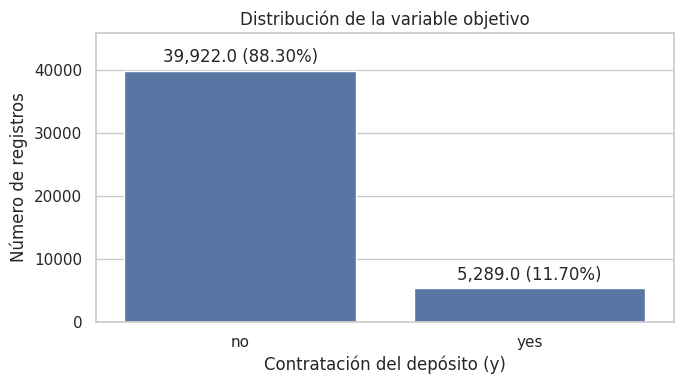

In [19]:
display(df["y"].value_counts(dropna=False).to_frame("cantidad"))
display((df["y"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("porcentaje"))

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="y", order=df["y"].value_counts().index)
plt.title("Distribución de la variable objetivo")
plt.xlabel("Contratación del depósito (y)")
plt.ylabel("Número de registros")

# Etiquetas con la cantidad y el porcentaje sobre las barras
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f"{height:,} ({(height / total) * 100:.2f}%)"
    ax.annotate(percentage,
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                xytext=(0, 3),
                textcoords='offset points')

# Para que las etiquetas no queden cortadas
plt.ylim(0, df["y"].value_counts().max() * 1.15)

plt.tight_layout()
plt.show()

## 12. Distribución de variables numéricas

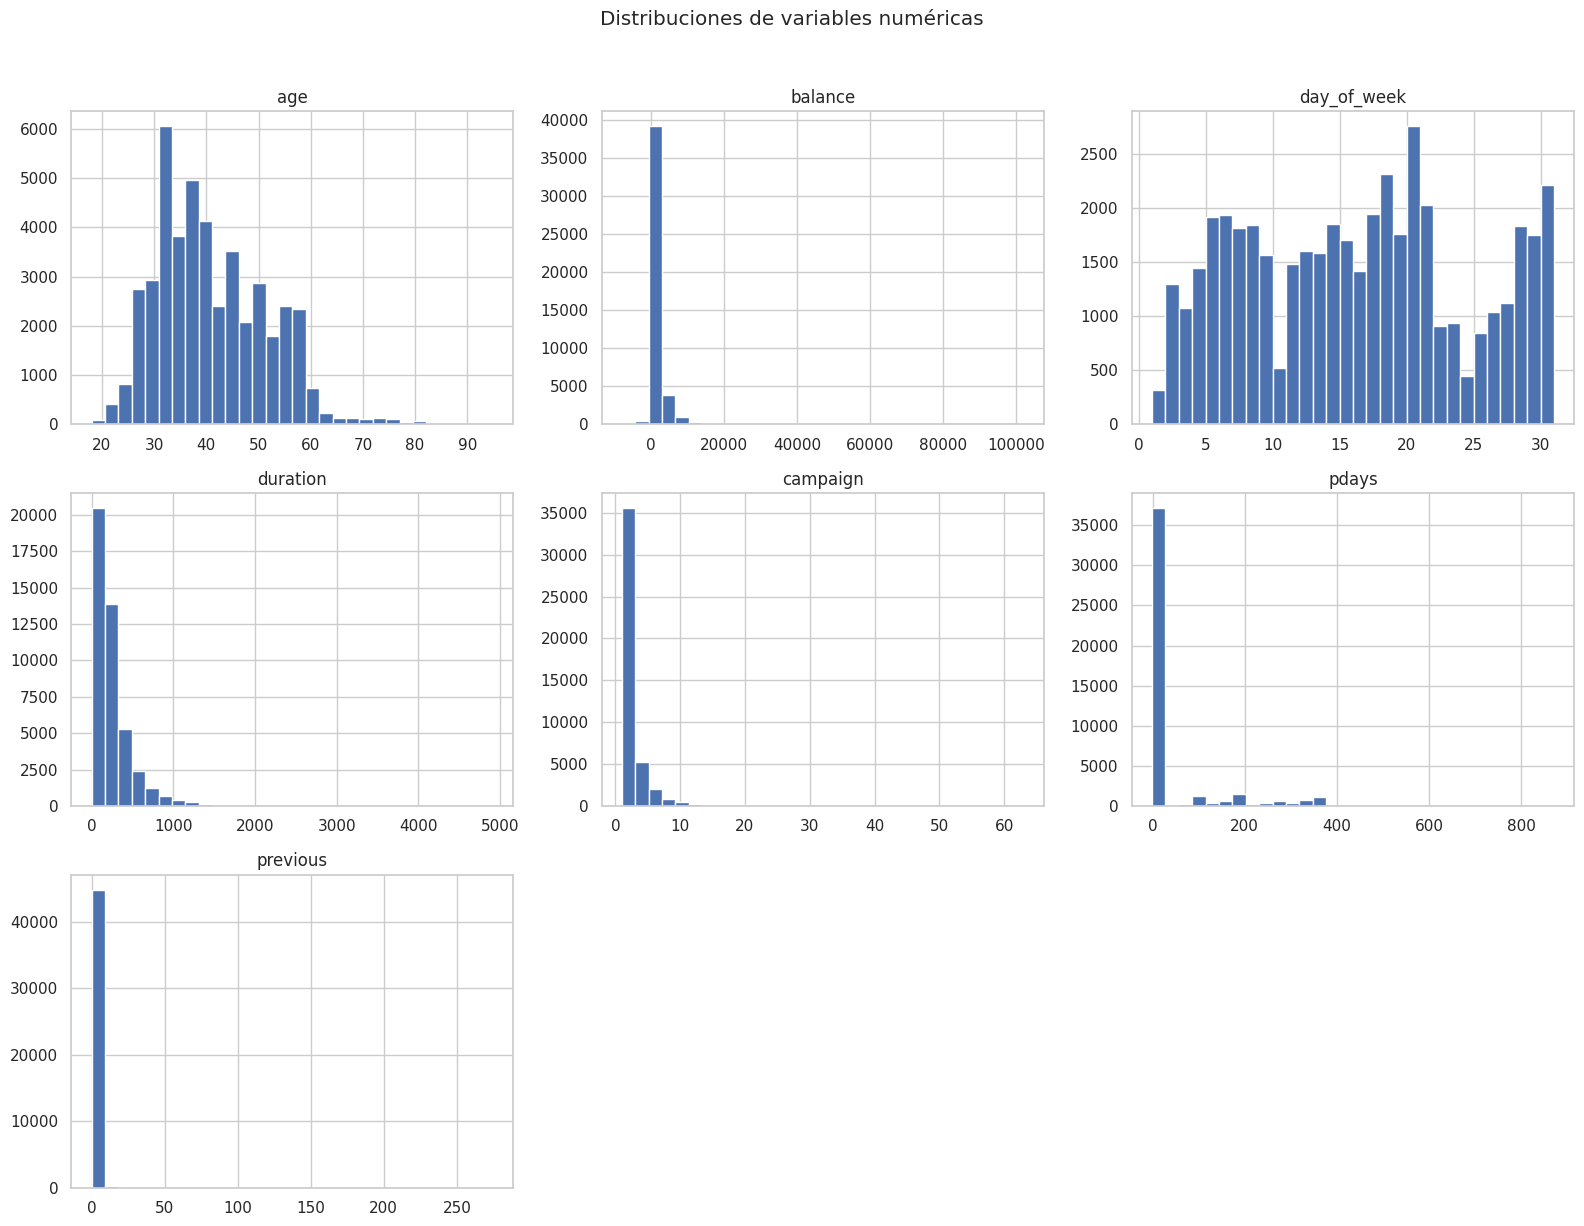

In [12]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
df[num_cols].hist(figsize=(16, 12), bins=30, edgecolor="white")
plt.suptitle("Distribuciones de variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

## 13. Distribución de variables categóricas

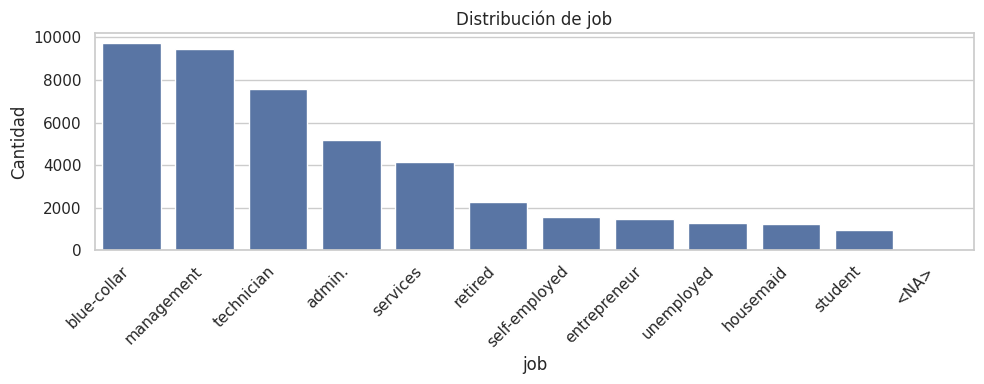

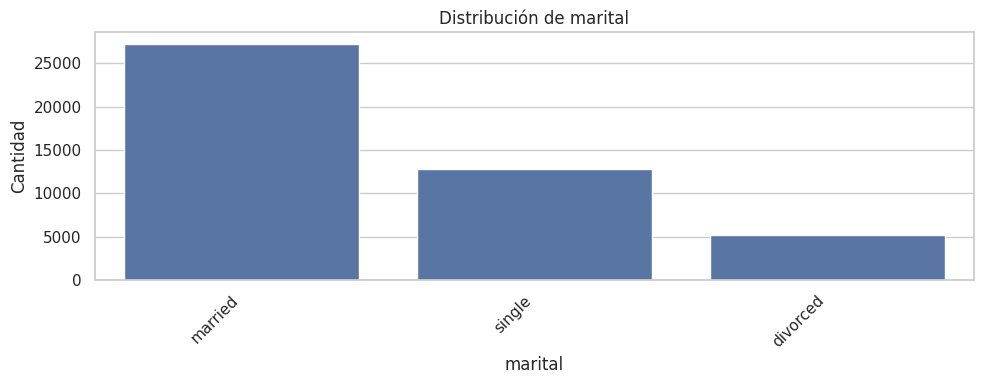

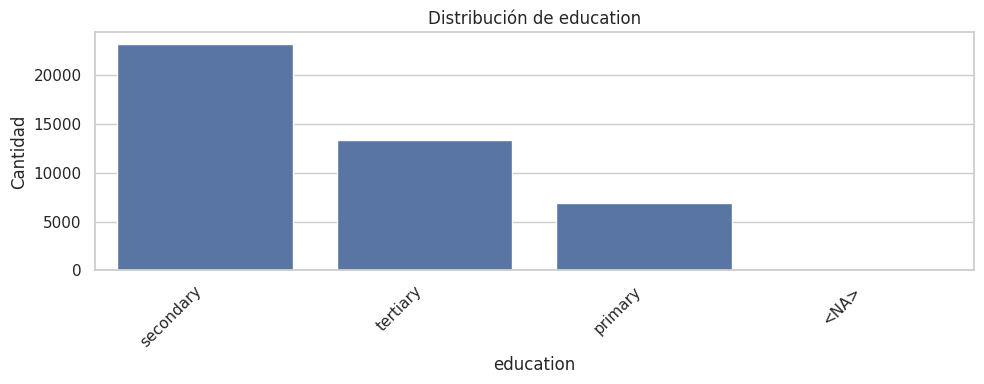

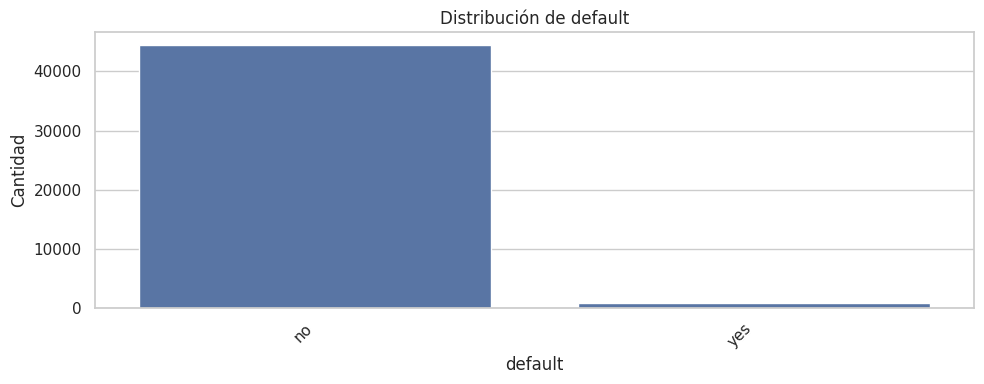

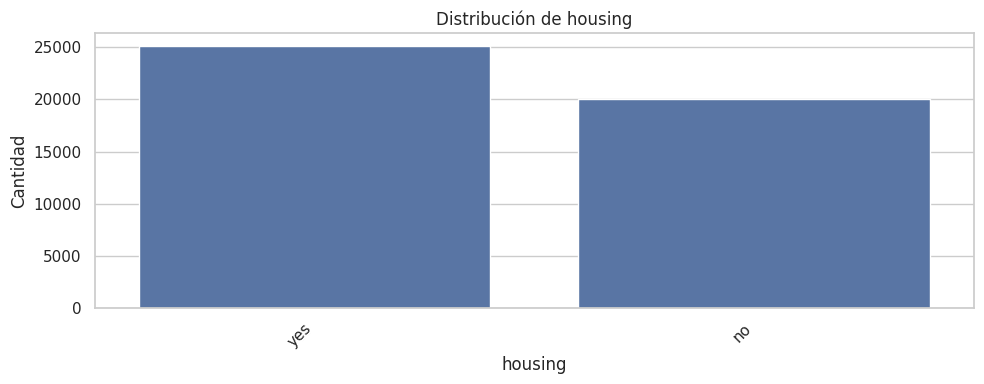

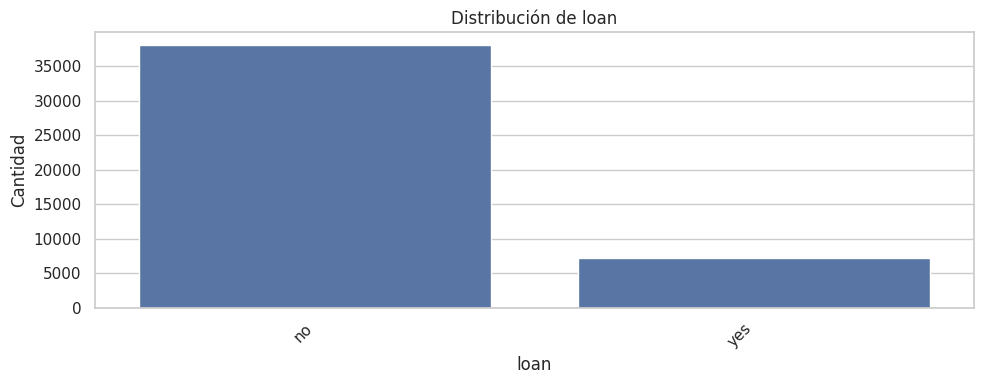

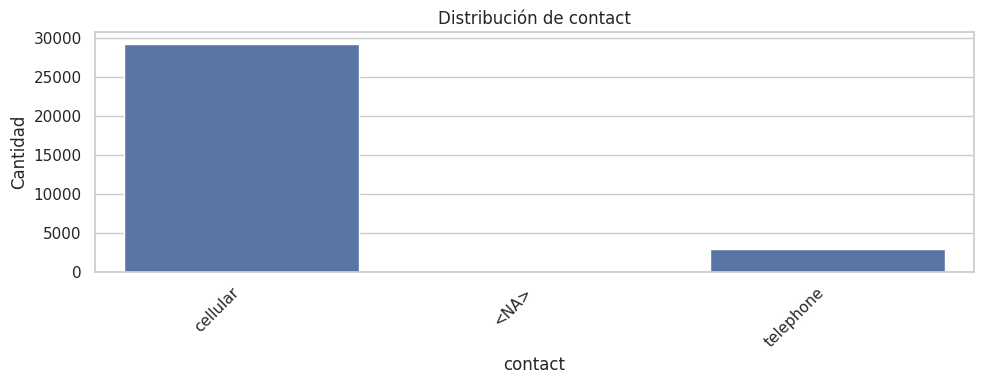

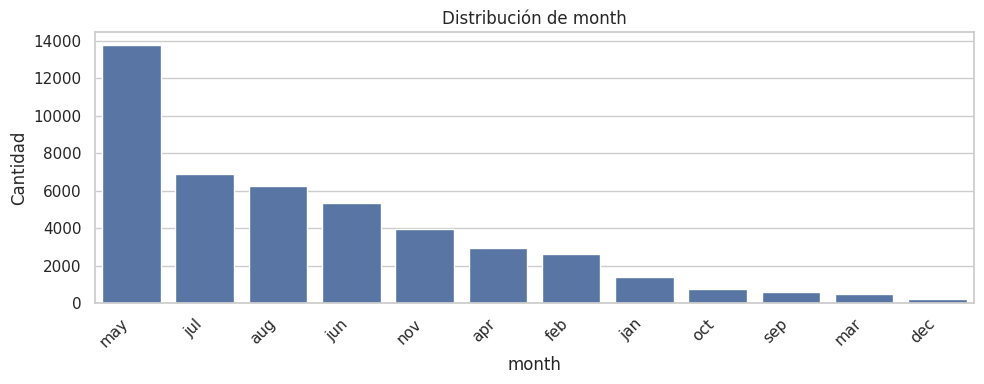

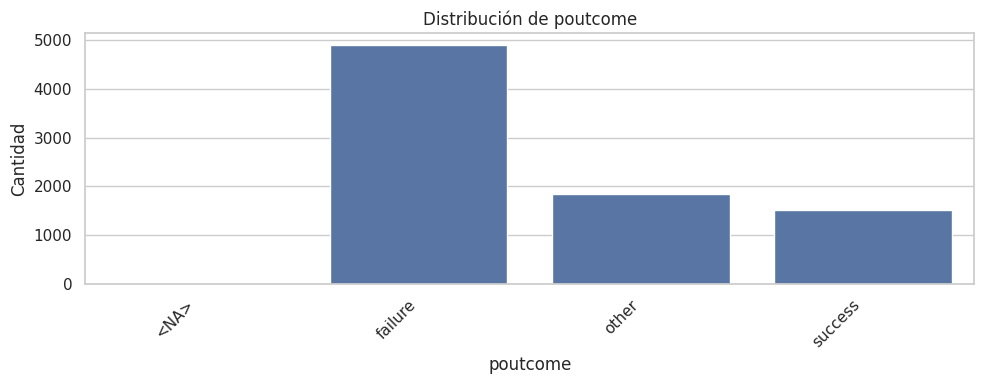

In [13]:
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for col in cat_cols:
    if col == "y":
        continue
    plt.figure(figsize=(10, 4))
    order = df[col].value_counts(dropna=False).head(15).index
    sns.countplot(data=df, x=col, order=order)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Cantidad")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 14. Correlaciones entre variables numéricas

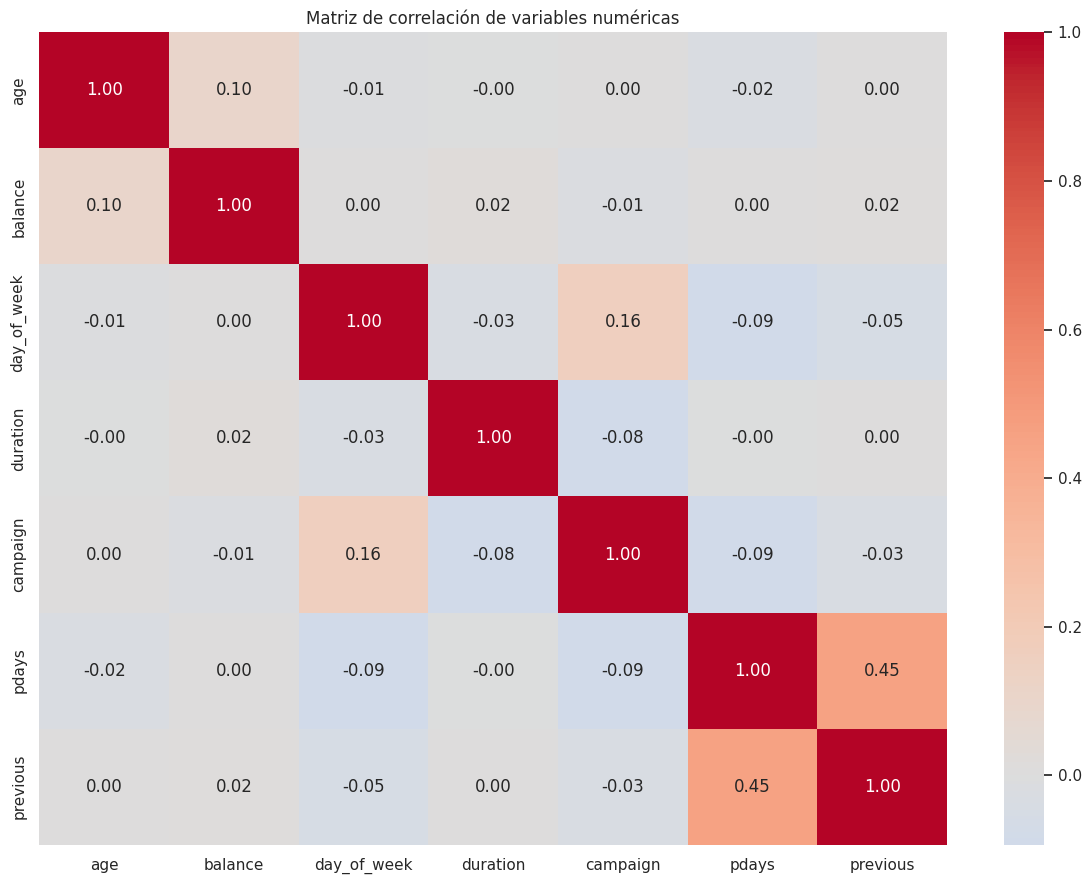

,age,balance,day_of_week,duration,campaign,pdays,previous
age,1.000,0.098,-0.009,-0.005,0.005,-0.024,0.001
balance,0.098,1.000,0.005,0.022,-0.015,0.003,0.017
day_of_week,-0.009,0.005,1.000,-0.030,0.162,-0.093,-0.052
duration,-0.005,0.022,-0.030,1.000,-0.085,-0.002,0.001
campaign,0.005,-0.015,0.162,-0.085,1.000,-0.089,-0.033
pdays,-0.024,0.003,-0.093,-0.002,-0.089,1.000,0.455
previous,0.001,0.017,-0.052,0.001,-0.033,0.455,1.000


In [14]:
corr = df.select_dtypes(include=np.number).corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()
display(corr.round(3))

## 15. Análisis de posibles valores atípicos

In [15]:
# La regla IQR identifica posibles extremos; no demuestra que sean errores.
outlier_rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < low) | (df[col] > high)
    outlier_rows.append({
        "variable": col,
        "min": df[col].min(),
        "max": df[col].max(),
        "limite_inferior_IQR": low,
        "limite_superior_IQR": high,
        "posibles_atipicos": int(mask.sum()),
        "porcentaje": round(mask.mean() * 100, 2)
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values("posibles_atipicos", ascending=False)
display(outlier_summary)

,variable,min,max,limite_inferior_IQR,limite_superior_IQR,posibles_atipicos,porcentaje
6,previous,0,275,0.0,0.0,8257,18.26
5,pdays,-1,871,-1.0,-1.0,8257,18.26
1,balance,-8019,102127,-1962.0,3462.0,4729,10.46
3,duration,0,4918,-221.0,643.0,3235,7.16
4,campaign,1,63,-2.0,6.0,3064,6.78
0,age,18,95,10.5,70.5,487,1.08
2,day_of_week,1,31,-11.5,40.5,0,0.00


### Criterio para tratar valores atípicos
No se deben eliminar automáticamente todos los valores señalados por IQR. Algunas variables pueden tener valores extremos reales o códigos especiales, por ejemplo `pdays = -1`. Las decisiones deben justificarse con el diccionario de datos y el contexto bancario.

## 16. Informe Pandas Profiling

In [16]:
profile = ProfileReport(
    df,
    title="Bank Marketing — Pandas Profiling",
    explorative=True,
    minimal=True
)
profile_path = OUTPUT_DIR / "bank_marketing_profiling.html"
profile.to_file(profile_path)
print("Informe guardado en:", profile_path)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 17/17 [00:00<00:00, 34.53it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Informe guardado en: entregables_preparacion_bank_marketing/bank_marketing_profiling.html


## 17. Limpieza de datos documentada

In [17]:
# Conservar el original y crear la versión de trabajo.
df_limpio = df.copy(deep=True)

# Normalizar espacios en las variables de texto.
for col in df_limpio.select_dtypes(include=["object", "string"]).columns:
    df_limpio[col] = df_limpio[col].astype("string").str.strip()

# Eliminar únicamente duplicados exactos detectados.
duplicados_antes = int(df_limpio.duplicated().sum())
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

print("Duplicados exactos eliminados:", duplicados_antes)
print("Dimensiones antes:", df.shape)
print("Dimensiones después:", df_limpio.shape)
print("Faltantes restantes:", int(df_limpio.isna().sum().sum()))

# No se imputan ni escalan variables aquí: la imputación y transformaciones deben ajustarse dentro del pipeline del modelado para evitar fuga de información.

Duplicados exactos eliminados: 0
Dimensiones antes: (45211, 17)
Dimensiones después: (45211, 17)
Faltantes restantes: 52124


## 18. Exportar dataset limpio sin balancear

In [18]:
clean_path = OUTPUT_DIR / "bank_marketing_limpio_sin_balancear.csv"
df_limpio.to_csv(clean_path, index=False)
print("Dataset limpio exportado:", clean_path)

Dataset limpio exportado: entregables_preparacion_bank_marketing/bank_marketing_limpio_sin_balancear.csv


**Nota:** aqui no se incluye codificación, escalado, creación de nuevas variables, SMOTE ni partición para modelado. Estos pasos corresponden al notebook 02_Modelado_Evaluacion_Bank_Marketing